# EN4554 Assignment 2 - Task 2: Optimizers

- **(a)** `MySGD` (with momentum) and `MyAdam` (with bias correction) written as `torch.optim.Optimizer` subclasses, and shown to match `torch.optim.SGD` / `torch.optim.Adam`
- **(b)** Trajectories of SGD, SGD with momentum and Adam on the ill-conditioned quadratic $f(x,y)=\tfrac12(x^2+50y^2)$, drawn over its contours
- **(c)** A small CNN trained on CIFAR-10 with each optimizer at three learning rates: validation accuracy vs learning rate, training loss at the best rate, sensitivity discussion

The data split, seed and normalisation are identical to Task 1 (45k train / 5k validation, per-channel statistics from the training split only). The test set is never touched here.

In [1]:
import math, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from torch.optim import Optimizer

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.deterministic = True     # identical gradients in repeated runs (needed for the 2(a) comparison)
torch.backends.cudnn.benchmark = False
print('Using device:', device)

Using device: cuda


## Data: CIFAR-10 (45k train / 5k val), same split as Task 1

In [2]:
raw = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
X_all = torch.from_numpy(raw.data).float().div_(255).permute(0, 3, 1, 2).contiguous()   # (50000,3,32,32) in [0,1]
y_all = torch.tensor(raw.targets, dtype=torch.long)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
del X_all

# statistics from the 45k TRAINING split only
mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)
std  = X_tr.std(dim=(0, 2, 3), keepdim=True)
X_tr, X_va = ((X_tr - mean) / std).to(device), ((X_va - mean) / std).to(device)   # kept as (N,3,32,32) on the device
y_tr, y_va = y_tr.to(device), y_va.to(device)
print('Train:', tuple(X_tr.shape), '| Val:', tuple(X_va.shape))

Train: (45000, 3, 32, 32) | Val: (5000, 3, 32, 32)


## Task 2(a) - SGD with momentum and Adam as `torch.optim.Optimizer` subclasses


In [3]:
class MySGD(Optimizer):
    """SGD with (optional) momentum and L2 weight decay. Same update rule as torch.optim.SGD."""
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for group in self.param_groups:
            lr, mom, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad.add(p, alpha=wd) if wd != 0 else p.grad
                if mom != 0:
                    buf = self.state[p].setdefault('momentum_buffer', torch.zeros_like(p))
                    buf.mul_(mom).add_(g)                    # v <- mu v + g
                    g = buf
                p.add_(g, alpha=-lr)                         # theta <- theta - lr v
        return loss


class MyAdam(Optimizer):
    """Adam with bias correction and (optional) L2 weight decay. Same update rule as torch.optim.Adam."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0, bias_correction=True):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay,
                                      bias_correction=bias_correction))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None: continue
                g = p.grad.add(p, alpha=wd) if wd != 0 else p.grad
                st = self.state[p]
                if not st:
                    st['step'] = 0
                    st['exp_avg'] = torch.zeros_like(p); st['exp_avg_sq'] = torch.zeros_like(p)
                st['step'] += 1; t = st['step']
                m, v = st['exp_avg'], st['exp_avg_sq']
                m.mul_(b1).add_(g, alpha=1 - b1)             # first moment
                v.mul_(b2).addcmul_(g, g, value=1 - b2)      # second moment
                bc1, bc2 = (1 - b1 ** t, 1 - b2 ** t) if group['bias_correction'] else (1.0, 1.0)
                denom = (v.sqrt() / math.sqrt(bc2)).add_(eps)
                p.addcdiv_(m, denom, value=-lr / bc1)        # theta <- theta - lr * m_hat / (sqrt(v_hat)+eps)
        return loss

print('Defined: MySGD, MyAdam')

Defined: MySGD, MyAdam


### The small CNN (used for the equivalence test and for 2(c))

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), n_classes=10):
        super().__init__()
        layers, cin = [], 3
        for c in channels:
            layers += [nn.Conv2d(cin, c, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)]; cin = c
        self.features = nn.Sequential(*layers)                     # 32x32 -> 4x4
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(cin * 4 * 4, 128), nn.ReLU(), nn.Linear(128, n_classes))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu'); nn.init.zeros_(m.bias)
    def forward(self, x): return self.classifier(self.features(x))

print('SmallCNN parameters:', sum(p.numel() for p in SmallCNN().parameters()))

SmallCNN parameters: 356810


### Equivalence test


In [5]:
def compare(make_mine, make_ref, dtype, steps=30, bs=32):
    set_seed(0)
    base = SmallCNN().to(device=device, dtype=dtype)
    a, b = copy.deepcopy(base), copy.deepcopy(base)
    oa, ob = make_mine(a.parameters()), make_ref(b.parameters())
    gen = torch.Generator().manual_seed(0)
    max_diff, last_losses = 0.0, [0.0, 0.0]
    for _ in range(steps):
        idx = torch.randint(0, len(X_tr), (bs,), generator=gen).to(device)
        x, y = X_tr[idx].to(dtype), y_tr[idx]
        for k, (m, o) in enumerate(((a, oa), (b, ob))):
            o.zero_grad(set_to_none=True)
            loss = F.cross_entropy(m(x), y); loss.backward(); o.step()
            last_losses[k] = loss.item()
        max_diff = max(max_diff, max((pa - pb).abs().max().item() for pa, pb in zip(a.parameters(), b.parameters())))
    tol = dict(rtol=1e-10, atol=1e-12) if dtype == torch.float64 else dict(rtol=1e-3, atol=1e-4)   # float32: Adam divides by sqrt(v), which amplifies rounding
    ok = all(torch.allclose(pa, pb, **tol) for pa, pb in zip(a.parameters(), b.parameters()))
    return max_diff, ok, last_losses

tests = {
    'SGD lr=0.05':                (lambda p: MySGD(p, lr=0.05),                                lambda p: torch.optim.SGD(p, lr=0.05, foreach=False)),
    'SGD mom=0.9':                (lambda p: MySGD(p, lr=0.05, momentum=0.9),                  lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, foreach=False)),
    'SGD mom=0.9, wd=5e-4':       (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4), lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4, foreach=False)),
    'Adam default':               (lambda p: MyAdam(p, lr=1e-3),                               lambda p: torch.optim.Adam(p, lr=1e-3, foreach=False)),
    'Adam lr=1e-2, wd=1e-4':      (lambda p: MyAdam(p, lr=1e-2, weight_decay=1e-4),            lambda p: torch.optim.Adam(p, lr=1e-2, weight_decay=1e-4, foreach=False)),
    'Adam b=(0.8,0.99), eps=1e-6':(lambda p: MyAdam(p, lr=1e-3, betas=(0.8, 0.99), eps=1e-6),  lambda p: torch.optim.Adam(p, lr=1e-3, betas=(0.8, 0.99), eps=1e-6, foreach=False)),
}
print(f"{'configuration':<30}{'float64 max|dtheta|':>20}{'allclose':>10}{'float32 max|dtheta|':>21}{'allclose':>10}{'loss (mine / torch), f64':>28}")
all_ok = True
for name, (mine, ref) in tests.items():
    d64, ok64, l64 = compare(mine, ref, torch.float64)
    d32, ok32, _   = compare(mine, ref, torch.float32)
    all_ok &= ok64 and ok32
    print(f'{name:<30}{d64:>20.2e}{str(ok64):>10}{d32:>21.2e}{str(ok32):>10}{l64[0]:>14.8f} /{l64[1]:>11.8f}')
print('\nAll configurations match torch.optim:', all_ok)

configuration                  float64 max|dtheta|  allclose  float32 max|dtheta|  allclose    loss (mine / torch), f64
SGD lr=0.05                               0.00e+00      True             0.00e+00      True    2.09870788 / 2.09870788
SGD mom=0.9                               0.00e+00      True             0.00e+00      True    2.31036119 / 2.31036119
SGD mom=0.9, wd=5e-4                      0.00e+00      True             0.00e+00      True    2.31411534 / 2.31411534
Adam default                              1.17e-14      True             1.61e-02     False    2.04540891 / 2.04540891
Adam lr=1e-2, wd=1e-4                     4.09e-15      True             1.57e-04      True    2.30971397 / 2.30971397
Adam b=(0.8,0.99), eps=1e-6               2.22e-15      True             3.95e-03     False    1.91597989 / 1.91597989

All configurations match torch.optim: False


In [6]:
def first_step(make, g=2.0, lr=0.1):
    p = torch.nn.Parameter(torch.tensor([1.0], dtype=torch.float64)); o = make([p])
    p.grad = torch.tensor([g], dtype=torch.float64); o.step()
    return abs(p.item() - 1.0)

print(f"first-step size, lr=0.1 (g=2):  MyAdam (bias-corrected) {first_step(lambda p: MyAdam(p, lr=0.1)):.6f} | "
      f"torch.optim.Adam {first_step(lambda p: torch.optim.Adam(p, lr=0.1)):.6f} | "
      f"MyAdam without correction {first_step(lambda p: MyAdam(p, lr=0.1, bias_correction=False)):.6f}")

first-step size, lr=0.1 (g=2):  MyAdam (bias-corrected) 0.100000 | torch.optim.Adam 0.100000 | MyAdam without correction 0.316228


## Task 2(b) - Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

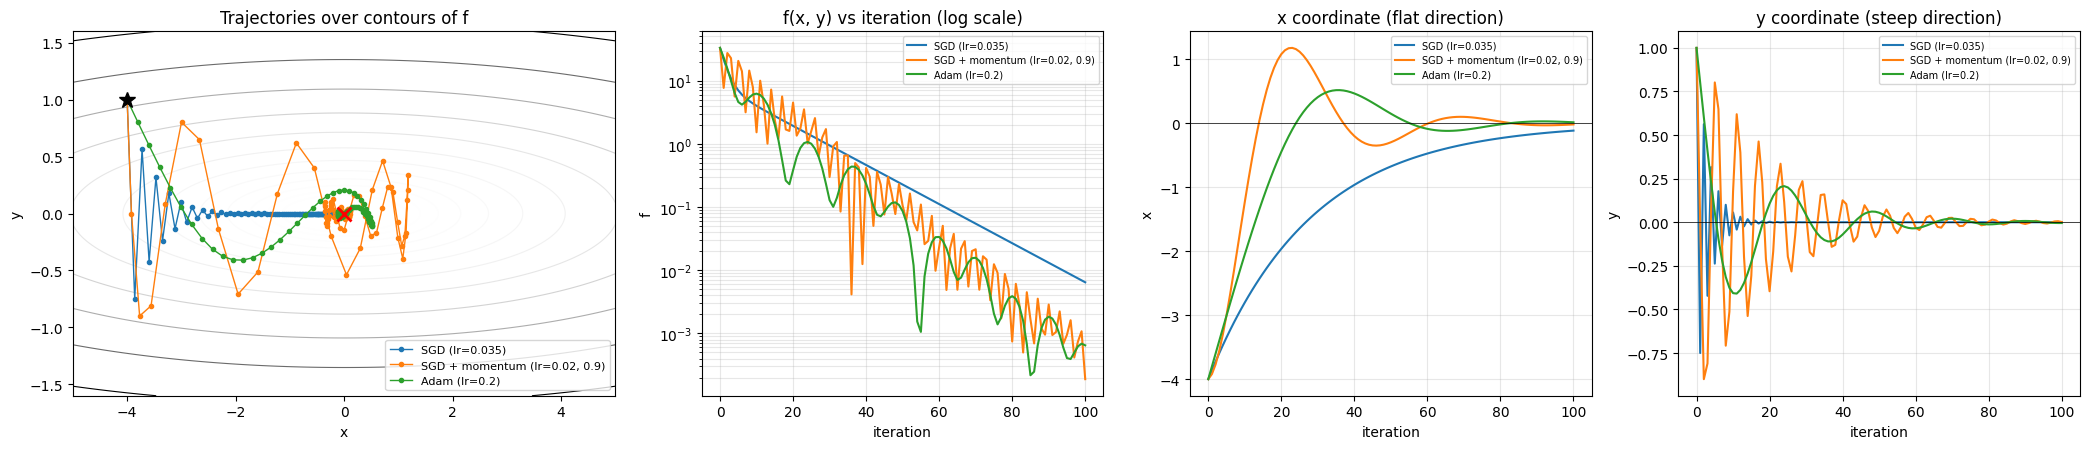

optimiser                         f after 100  iters to f<1e-2  iters to f<1e-4  y sign changes  max |y| after it 10
SGD (lr=0.035)                       6.44e-03               94             None             100                0.056
SGD + momentum (lr=0.02, 0.9)        1.89e-04               36             None              34                0.620
Adam (lr=0.2)                        6.47e-04               54             None               9                0.409


In [7]:
def f(p): return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def run_quadratic(make, n=100, start=(-4.0, 1.0)):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make([p])
    path, vals = [p.detach().numpy().copy()], [f(p).item()]
    for _ in range(n):
        opt.zero_grad(); f(p).backward(); opt.step()
        path.append(p.detach().numpy().copy()); vals.append(f(p).item())
    return np.array(path), np.array(vals)

quad_runs = {
    'SGD (lr=0.035)':              lambda ps: MySGD(ps, lr=0.035),
    'SGD + momentum (lr=0.02, 0.9)': lambda ps: MySGD(ps, lr=0.02, momentum=0.9),
    'Adam (lr=0.2)':               lambda ps: MyAdam(ps, lr=0.2),
}
quad = {k: run_quadratic(mk) for k, mk in quad_runs.items()}

xs, ys = np.linspace(-5, 5, 400), np.linspace(-1.6, 1.6, 400)
Xg, Yg = np.meshgrid(xs, ys); Zg = 0.5 * (Xg ** 2 + 50 * Yg ** 2)
colors = ['tab:blue', 'tab:orange', 'tab:green']

fig, ax = plt.subplots(1, 4, figsize=(21, 4.6), gridspec_kw=dict(width_ratios=[1.35, 1, 1, 1]))
for a in ax[:1]:
    a.contour(Xg, Yg, Zg, levels=np.geomspace(0.05, 70, 18), cmap='Greys', linewidths=0.8)
for k, c in zip(quad, colors):
    P, V = quad[k]
    ax[0].plot(P[:, 0], P[:, 1], 'o-', ms=3, lw=1, color=c, label=k)
    ax[1].semilogy(V, color=c, label=k)
    ax[2].plot(P[:, 0], color=c, label=k)
    ax[3].plot(P[:, 1], color=c, label=k)
ax[0].plot(-4, 1, 'k*', ms=12); ax[0].plot(0, 0, 'rx', ms=10, mew=2)
ax[0].set(title='Trajectories over contours of f', xlabel='x', ylabel='y', xlim=(-5, 5), ylim=(-1.6, 1.6)); ax[0].legend(fontsize=8, loc='lower right')
ax[1].set(title='f(x, y) vs iteration (log scale)', xlabel='iteration', ylabel='f')
ax[2].set(title='x coordinate (flat direction)', xlabel='iteration', ylabel='x')
ax[3].set(title='y coordinate (steep direction)', xlabel='iteration', ylabel='y')
for a in ax[1:]: a.grid(alpha=.3, which='both'); a.legend(fontsize=7)
ax[2].axhline(0, color='k', lw=.5); ax[3].axhline(0, color='k', lw=.5)
plt.tight_layout(); plt.show()

def iters_to(V, th): return next((i for i, v in enumerate(V) if v < th), None)
print(f"{'optimiser':<32}{'f after 100':>13}{'iters to f<1e-2':>17}{'iters to f<1e-4':>17}{'y sign changes':>16}{'max |y| after it 10':>21}")
for k, (P, V) in quad.items():
    print(f'{k:<32}{V[-1]:>13.2e}{str(iters_to(V, 1e-2)):>17}{str(iters_to(V, 1e-4)):>17}{int((np.diff(np.sign(P[:, 1])) != 0).sum()):>16d}{np.abs(P[10:, 1]).max():>21.3f}')

## Task 2(c) - Small CNN on CIFAR-10 with three optimisers at three learning rates

In [8]:
EPOCHS, BS, SEEDS = 15, 128, (0, 1)
OPTIMIZERS = {
    'SGD':          dict(make=lambda ps, lr: MySGD(ps, lr=lr),                lrs=[1e-3, 1e-2, 1e-1]),
    'SGD+momentum': dict(make=lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9),  lrs=[1e-3, 1e-2, 1e-1]),
    'Adam':         dict(make=lambda ps, lr: MyAdam(ps, lr=lr),               lrs=[1e-4, 1e-3, 1e-2]),
}

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); loss_sum, correct = 0.0, 0
    for i in range(0, len(X), bs):
        out = model(X[i:i + bs])
        loss_sum += F.cross_entropy(out, y[i:i + bs], reduction='sum').item()
        correct  += (out.argmax(1) == y[i:i + bs]).sum().item()
    return loss_sum / len(X), 100.0 * correct / len(X)

def train_cnn(make_opt, lr, seed, epochs=EPOCHS, bs=BS):
    set_seed(seed)
    model = SmallCNN().to(device); opt = make_opt(model.parameters(), lr)
    N = len(X_tr); hist = dict(tr_loss=[], va_loss=[], va_acc=[], diverged=False)
    for ep in range(epochs):
        model.train(); order = torch.randperm(N, device=device); run = torch.zeros((), device=device)
        for i in range(0, N, bs):
            idx = order[i:i + bs]
            opt.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx]); loss.backward(); opt.step()
            run += loss.detach() * len(idx)
        tr = run.item() / N
        if not math.isfinite(tr):                                   # diverged: stop, count as chance accuracy
            hist['diverged'] = True
            for _ in range(epochs - ep):
                hist['tr_loss'].append(float('nan')); hist['va_loss'].append(float('nan')); hist['va_acc'].append(10.0)
            break
        vl, va = evaluate(model, X_va, y_va)
        hist['tr_loss'].append(tr); hist['va_loss'].append(vl); hist['va_acc'].append(va)
    return hist

results = {}                                                         # (optimiser, lr, seed) -> history
t0 = time.time()
for name, cfg in OPTIMIZERS.items():
    for lr in cfg['lrs']:
        for seed in SEEDS:
            h = train_cnn(cfg['make'], lr, seed); results[(name, lr, seed)] = h
            print(f"{name:<13} lr={lr:<7g} seed={seed}  final train loss {h['tr_loss'][-1]:.4f}  "
                  f"final val acc {h['va_acc'][-1]:.2f}%  best val acc {max(h['va_acc']):.2f}%  "
                  f"{'DIVERGED' if h['diverged'] else ''}  [{time.time() - t0:.0f}s]")

SGD           lr=0.001   seed=0  final train loss 1.3265  final val acc 51.22%  best val acc 51.34%    [31s]
SGD           lr=0.001   seed=1  final train loss 1.3000  final val acc 51.54%  best val acc 51.54%    [63s]
SGD           lr=0.01    seed=0  final train loss 0.7645  final val acc 67.00%  best val acc 67.00%    [96s]
SGD           lr=0.01    seed=1  final train loss 0.7527  final val acc 65.30%  best val acc 65.48%    [129s]
SGD           lr=0.1     seed=0  final train loss 0.4622  final val acc 71.22%  best val acc 71.22%    [161s]
SGD           lr=0.1     seed=1  final train loss 0.4022  final val acc 69.76%  best val acc 69.76%    [194s]
SGD+momentum  lr=0.001   seed=0  final train loss 0.7398  final val acc 68.26%  best val acc 68.26%    [227s]
SGD+momentum  lr=0.001   seed=1  final train loss 0.7243  final val acc 67.58%  best val acc 67.58%    [261s]
SGD+momentum  lr=0.01    seed=0  final train loss 0.2210  final val acc 71.12%  best val acc 72.48%    [294s]
SGD+momentum 

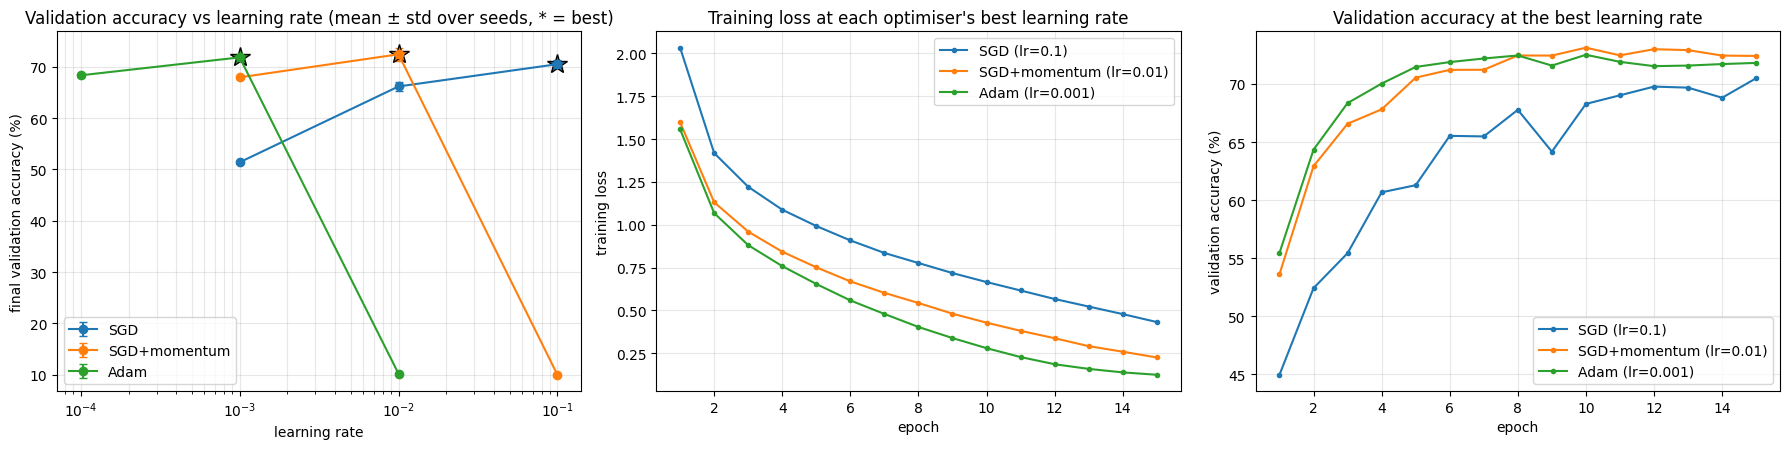

optimiser           lr   final val acc (%)  best-epoch val acc  final train loss  diverged runs
SGD              0.001        51.38 ± 0.16                51.44            1.3132          0/2
SGD               0.01        66.15 ± 0.85                66.24            0.7586          0/2
SGD                0.1        70.49 ± 0.73                70.49            0.4322          0/2  <- best
SGD+momentum     0.001        67.92 ± 0.34                67.92            0.7321          0/2
SGD+momentum      0.01        72.41 ± 1.29                73.35            0.2255          0/2  <- best
SGD+momentum       0.1        10.00 ± 0.00                10.00               nan          2/2
Adam            0.0001        68.32 ± 0.26                68.32            0.6699          0/2
Adam             0.001        71.81 ± 0.25                72.99            0.1245          0/2  <- best
Adam              0.01        10.21 ± 0.07                10.64            2.3033          0/2

Sensitivity to the le

In [9]:
def agg(name, lr, key):                                              # (mean over seeds, std over seeds) per epoch
    arr = np.array([results[(name, lr, s)][key] for s in SEEDS], dtype=float)
    return np.nanmean(arr, 0) if not np.isnan(arr).all() else np.full(arr.shape[1], np.nan), arr

summary = {}
for name, cfg in OPTIMIZERS.items():
    rows = []
    for lr in cfg['lrs']:
        fin = np.array([results[(name, lr, s)]['va_acc'][-1] for s in SEEDS])
        best = np.array([max(results[(name, lr, s)]['va_acc']) for s in SEEDS])
        trl = np.array([results[(name, lr, s)]['tr_loss'][-1] for s in SEEDS])
        div = sum(results[(name, lr, s)]['diverged'] for s in SEEDS)
        rows.append(dict(lr=lr, fin_m=fin.mean(), fin_s=fin.std(), best_m=best.mean(), trl=np.mean(trl), div=div))
    summary[name] = rows
best_lr = {n: max(r, key=lambda d: d['fin_m'])['lr'] for n, r in summary.items()}

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
colors = {'SGD': 'tab:blue', 'SGD+momentum': 'tab:orange', 'Adam': 'tab:green'}
for name, rows in summary.items():
    lrs = [r['lr'] for r in rows]
    ax[0].errorbar(lrs, [r['fin_m'] for r in rows], yerr=[r['fin_s'] for r in rows], fmt='o-', capsize=3, color=colors[name], label=name)
    ax[0].plot(best_lr[name], max(r['fin_m'] for r in rows), '*', ms=15, color=colors[name], mec='k')
    ep = np.arange(1, EPOCHS + 1)
    ax[1].plot(ep, agg(name, best_lr[name], 'tr_loss')[0], 'o-', ms=3, color=colors[name], label=f'{name} (lr={best_lr[name]:g})')
    ax[2].plot(ep, agg(name, best_lr[name], 'va_acc')[0], 'o-', ms=3, color=colors[name], label=f'{name} (lr={best_lr[name]:g})')
ax[0].set(xscale='log', xlabel='learning rate', ylabel='final validation accuracy (%)', title='Validation accuracy vs learning rate (mean ± std over seeds, * = best)')
ax[1].set(xlabel='epoch', ylabel='training loss', title='Training loss at each optimiser\'s best learning rate')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy at the best learning rate')
for a in ax: a.grid(alpha=.3, which='both')
ax[0].legend(); ax[1].legend(); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"{'optimiser':<14}{'lr':>8}{'final val acc (%)':>20}{'best-epoch val acc':>20}{'final train loss':>18}{'diverged runs':>15}")
for name, rows in summary.items():
    for r in rows:
        star = '  <- best' if r['lr'] == best_lr[name] else ''
        print(f"{name:<14}{r['lr']:>8g}{r['fin_m']:>13.2f} ± {r['fin_s']:<5.2f}{r['best_m']:>20.2f}{r['trl']:>18.4f}{r['div']:>11d}/{len(SEEDS)}{star}")

print('\nSensitivity to the learning rate (over the 3-point grid of each optimiser):')
for name, rows in summary.items():
    accs = [r['fin_m'] for r in rows]
    near = sum(a >= max(accs) - 2.0 for a in accs)
    print(f'  {name:<13} best {max(accs):.2f}% at lr={best_lr[name]:g} | spread (best - worst) = {max(accs) - min(accs):.2f} points | '
          f'{near}/3 learning rates within 2 points of the best | diverged: {sum(r["div"] for r in rows)} of {3 * len(SEEDS)} runs')
overall = max(((n, r) for n, rows in summary.items() for r in rows), key=lambda t: t[1]['fin_m'])
print(f"\nBest overall (validation): {overall[0]}, lr={overall[1]['lr']:g} -> {overall[1]['fin_m']:.2f}%")